# MLSP . Module II — TA Session 06
## From Kernel PCA to Learned Representations

**Amirkabir University of Technology · Department of Electrical Engineering**

**Teaching Assistant: Parisa Absavaran**  
**Notebook Author & Presenter: Parisa Absavaran**

## Learning objectives
- Compare linear PCA with Kernel PCA and identify failure modes.
- Distinguish fixed-dictionary sparse coding from dictionary learning.
- Understand the probabilistic latent representation of a Variational Autoencoder (VAE).
- Interpret the reconstruction term, KL divergence, reparameterization, latent interpolation, and prior sampling.

| Experiment | Topic |
|---|---:|
| 1 | PCA vs. Kernel PCA and failure analysis |
| 2 | Fixed vs. learned dictionaries |
| 3 | Variational Autoencoder |
| 4 | Latent-space analysis |
| 5 | Optional extensions and discussion |

The experiments use built-in or synthetic datasets; no external dataset download is required.

In [28]:
# If needed in Google Colab:
# %pip install -q numpy matplotlib scikit-learn torch

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles, load_digits
from sklearn.decomposition import PCA, KernelPCA, DictionaryLearning, sparse_encode
from sklearn.metrics import mean_squared_error
from sklearn.feature_extraction.image import extract_patches_2d
from sklearn.model_selection import train_test_split
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| Device:", device)

PyTorch: 2.14.1+cpu | Device: cpu


# Experiment 1 — PCA vs. Kernel PCA

## 1.1 Why can a linear subspace be insufficient?
PCA finds directions that explain the largest **linear** variance. It may not represent curved or nonlinear geometry well. We use concentric circles; labels are shown for visualization, but the dimensionality-reduction methods are unsupervised.

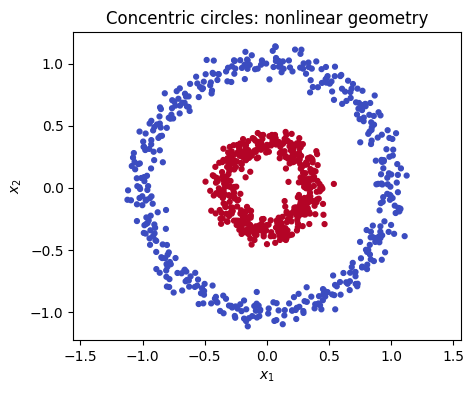

In [29]:
X, y = make_circles(n_samples=900, factor=0.35, noise=0.06, random_state=SEED)
plt.figure(figsize=(5,4))
plt.scatter(X[:,0], X[:,1], c=y, cmap="coolwarm", s=12)
plt.title("Concentric circles: nonlinear geometry")
plt.xlabel("$x_1$"); plt.ylabel("$x_2$"); plt.axis("equal"); plt.show()

## 1.2 Linear PCA
Project the two-dimensional data onto one principal component. This intentionally restrictive projection helps us inspect what is lost.

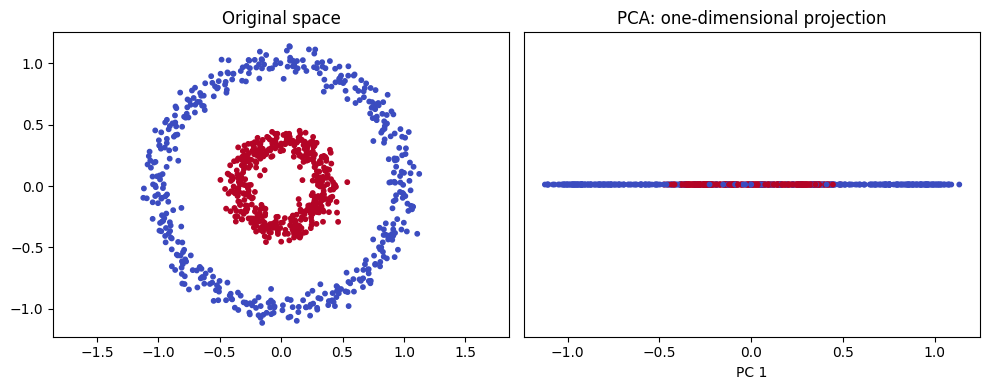

In [30]:
Zp = PCA(n_components=1).fit_transform(X)
fig, ax = plt.subplots(1,2,figsize=(10,4))
ax[0].scatter(X[:,0],X[:,1],c=y,cmap="coolwarm",s=10); ax[0].set_title("Original space"); ax[0].axis("equal")
ax[1].scatter(Zp[:,0],np.zeros(len(Zp)),c=y,cmap="coolwarm",s=10); ax[1].set_title("PCA: one-dimensional projection"); ax[1].set_xlabel("PC 1"); ax[1].set_yticks([])
plt.tight_layout(); plt.show()

## 1.3 RBF Kernel PCA
Kernel PCA performs PCA in an implicit feature space using a kernel matrix. For the RBF kernel,

$$
k(x_i,x_j)=\exp(-\gamma\|x_i-x_j\|_2^2).
$$

The kernel parameter controls the similarity scale. We start with a moderate value.

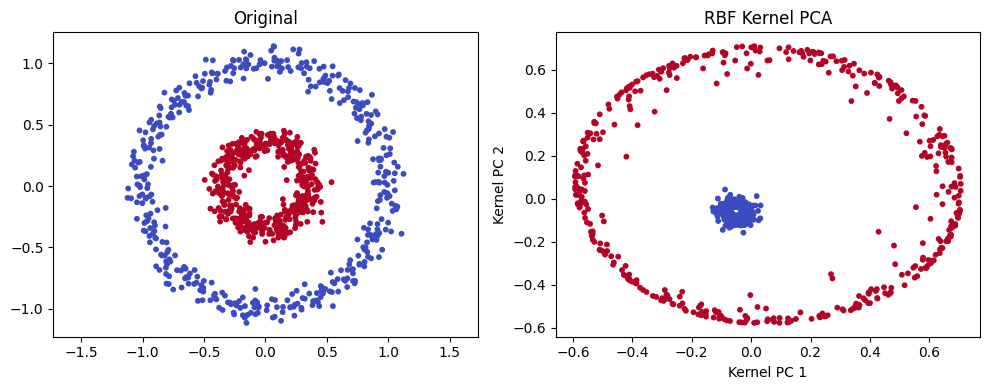

In [31]:
kpca = KernelPCA(n_components=2, kernel="rbf", gamma=8,
                 eigen_solver="arpack", random_state=SEED)
Zk = kpca.fit_transform(X)
fig, ax = plt.subplots(1,2,figsize=(10,4))
ax[0].scatter(X[:,0],X[:,1],c=y,cmap="coolwarm",s=10); ax[0].set_title("Original"); ax[0].axis("equal")
ax[1].scatter(Zk[:,0],Zk[:,1],c=y,cmap="coolwarm",s=10); ax[1].set_title("RBF Kernel PCA"); ax[1].set_xlabel("Kernel PC 1"); ax[1].set_ylabel("Kernel PC 2")
plt.tight_layout(); plt.show()

## 1.4 Failure analysis: kernel sensitivity
Kernel PCA does not eliminate modeling choices. The next experiment changes `gamma`. Look for embeddings that become compressed, fragmented, or otherwise less useful.

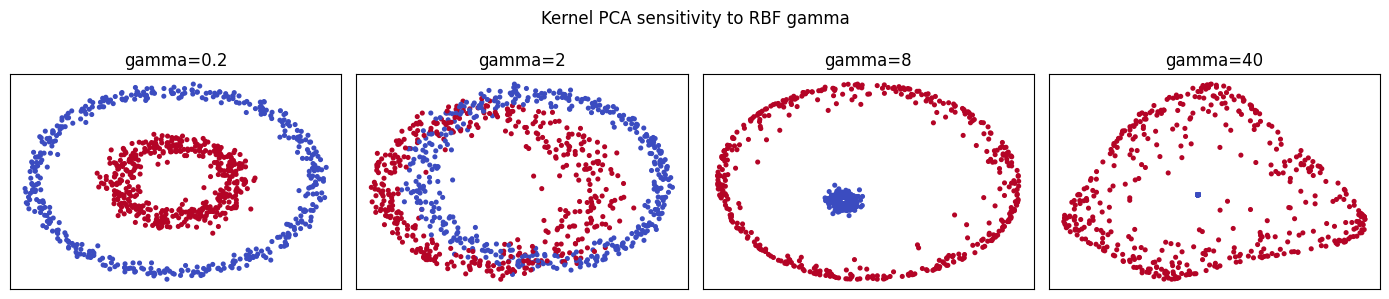

In [32]:
fig, axes = plt.subplots(1,4,figsize=(14,3))
for ax,g in zip(axes,[0.2,2,8,40]):
    Z = KernelPCA(n_components=2,kernel="rbf",gamma=g,
                  eigen_solver="arpack",random_state=SEED).fit_transform(X)
    ax.scatter(Z[:,0],Z[:,1],c=y,cmap="coolwarm",s=7)
    ax.set_title(f"gamma={g}"); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Kernel PCA sensitivity to RBF gamma"); plt.tight_layout(); plt.show()

### Discussion — Kernel PCA limitations
- **Kernel choice:** the kernel defines what counts as similar.
- **Hyperparameter sensitivity:** RBF `gamma` controls the locality of similarity.
- **Computational cost:** the kernel matrix has size \(N\times N\).
- **Out-of-sample mapping:** new observations must be related to training samples; pre-image reconstruction is not generally straightforward.
- **Task mismatch:** a visually appealing embedding is not automatically useful for classification or detection.

**Discuss:** Does a visually separated embedding prove that Kernel PCA is better for every downstream task? What else should be evaluated?

# Experiment 2 — From Sparse Coding to Dictionary Learning

## 2.1 Fixed dictionary vs. learned dictionary
Week 5 introduced sparse representation:

$$
x\approx D\alpha,
$$

where columns of \(D\) are atoms and only a few coefficients in \(\alpha\) should be active. With a **fixed dictionary**, we estimate the coefficients. With **dictionary learning**, both the dictionary and sparse codes are adapted to the data.

We use small patches from the built-in scikit-learn digits dataset.

In [33]:
digits = load_digits()
images = digits.images.astype(np.float32)/16.0
patches=[]
for im in images:
    patches.extend(extract_patches_2d(im,(6,6),max_patches=4,random_state=SEED))
patches=np.asarray(patches,dtype=np.float32)
Xp=patches.reshape(len(patches),-1)
print("Patch matrix:",Xp.shape)

Patch matrix: (7188, 36)


## 2.2 Construct a fixed 2-D DCT dictionary
A fixed transform dictionary is a useful baseline. Each atom is normalized to unit norm.

In [34]:
def dct_basis(n):
    B=np.zeros((n,n),dtype=np.float32)
    for k in range(n):
        a=np.sqrt(1/n) if k==0 else np.sqrt(2/n)
        for i in range(n):
            B[k,i]=a*np.cos(np.pi*(2*i+1)*k/(2*n))
    return B
B=dct_basis(6)
D_fixed=np.array([np.outer(B[i],B[j]).ravel() for i in range(6) for j in range(6)])
D_fixed/=np.linalg.norm(D_fixed,axis=1,keepdims=True)+1e-12
print("Fixed dictionary:",D_fixed.shape)

Fixed dictionary: (36, 36)


## 2.3 Sparse coding with the fixed dictionary
We use Orthogonal Matching Pursuit (OMP) to estimate sparse coefficients. The number of nonzero coefficients controls representation complexity.

In [35]:
sparsity=6
A_fixed=sparse_encode(Xp,D_fixed,algorithm="omp",n_nonzero_coefs=sparsity)
R_fixed=A_fixed@D_fixed
print("Fixed DCT reconstruction MSE:",mean_squared_error(Xp,R_fixed))
print("Mean active coefficients:",np.mean(np.sum(np.abs(A_fixed)>1e-8,axis=1)))

Fixed DCT reconstruction MSE: 0.04132925346493721
Mean active coefficients: 6.0


## 2.4 Learn a dictionary from data
Dictionary learning alternates between sparse-code estimation and dictionary updates. This is a non-convex optimization problem and does not guarantee a global optimum.

In [36]:
rng=np.random.default_rng(SEED)
perm=rng.permutation(len(Xp))
n_train=min(5400, int(0.75*len(Xp)))
train_idx, test_idx=perm[:n_train], perm[n_train:]
Xtrain_dict, Xtest_dict=Xp[train_idx], Xp[test_idx]
print("Dictionary-learning patches:",Xtrain_dict.shape,
      "| Held-out patches:",Xtest_dict.shape)
model=DictionaryLearning(n_components=36,alpha=0.8,max_iter=35,
    fit_algorithm="lars",transform_algorithm="omp",
    transform_n_nonzero_coefs=sparsity,random_state=SEED,n_jobs=-1)
A_learn=model.fit_transform(Xtrain_dict)
D_learn=model.components_
R_learn=A_learn@D_learn
print("Learned dictionary MSE:",mean_squared_error(Xtrain_dict,R_learn))
A_base=sparse_encode(Xtrain_dict,D_fixed,algorithm="omp",n_nonzero_coefs=sparsity)
print("Fixed DCT MSE on same subset:",mean_squared_error(Xtrain_dict,A_base@D_fixed))

Dictionary-learning patches: (5391, 36) | Held-out patches: (1797, 36)
Learned dictionary MSE: 0.05377154667868551
Fixed DCT MSE on same subset: 0.04159506782889366


## 2.5 Visualize dictionary atoms
Each atom is an elementary local pattern. A learned dictionary adapts these patterns to the training patches.

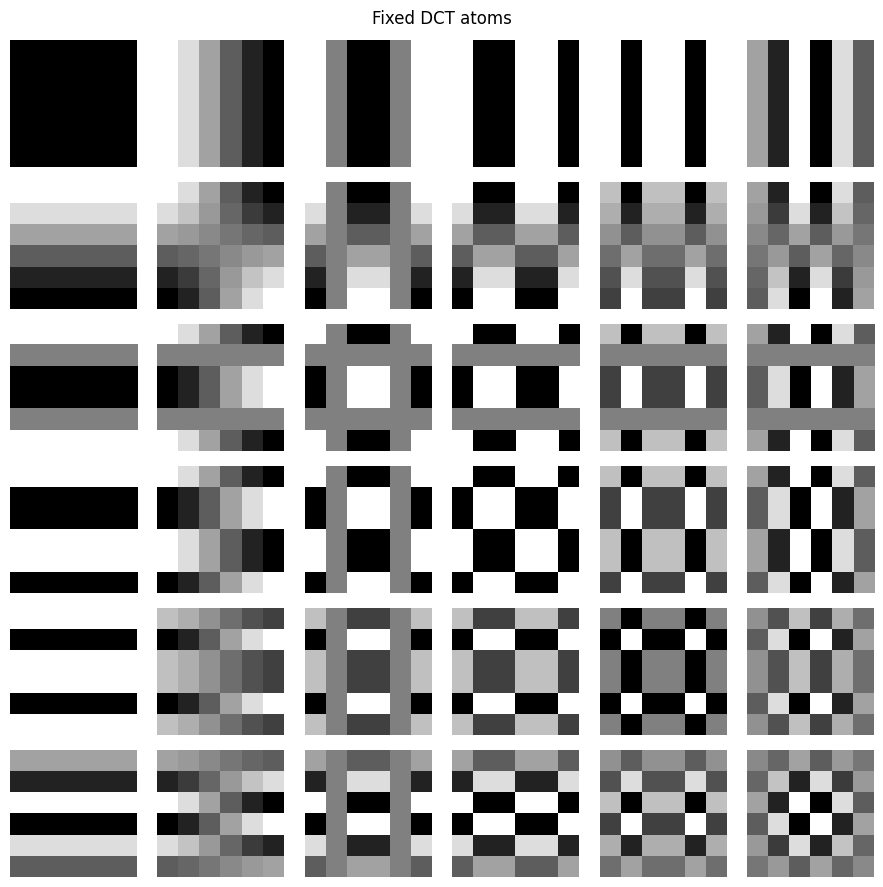

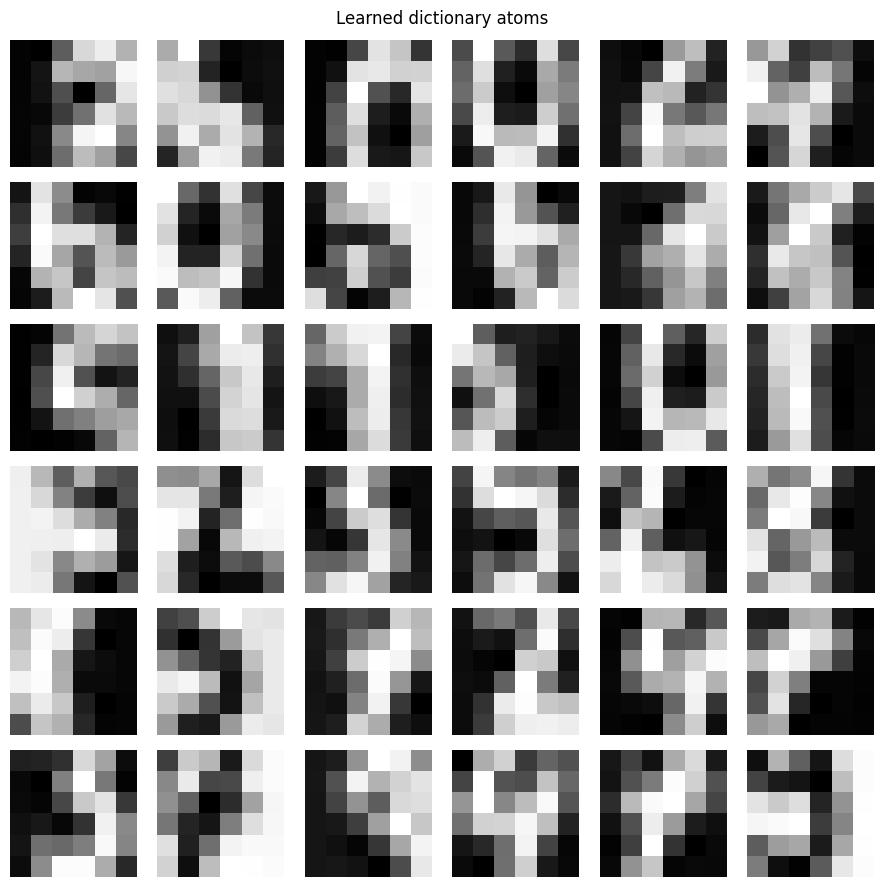

In [37]:
def show_atoms(atoms,title,ncols=6):
    n=len(atoms); nrows=int(np.ceil(n/ncols))
    fig,axes=plt.subplots(nrows,ncols,figsize=(ncols*1.5,nrows*1.5))
    axes=np.asarray(axes).reshape(-1)
    for i,ax in enumerate(axes):
        ax.axis("off")
        if i<n: ax.imshow(atoms[i].reshape(6,6),cmap="gray")
    fig.suptitle(title); plt.tight_layout(); plt.show()
show_atoms(D_fixed,"Fixed DCT atoms")
show_atoms(D_learn,"Learned dictionary atoms")

## 2.6 Compare patch reconstructions
We inspect held-out patches. Reconstruction error is useful, but visual artifacts, stability, computational cost, and generalization also matter.

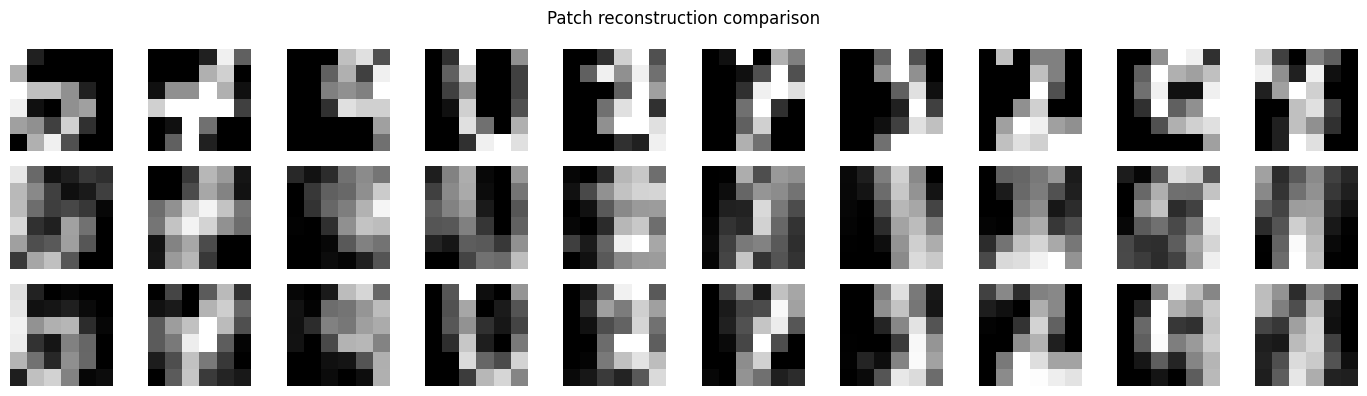

In [38]:
Xdemo=Xp[test_idx[:10]]
Af=sparse_encode(Xdemo,D_fixed,algorithm="omp",n_nonzero_coefs=sparsity)
Al=model.transform(Xdemo)
arrays=[Xdemo,Af@D_fixed,Al@D_learn]
fig,axes=plt.subplots(3,10,figsize=(14,4))
for r,arr in enumerate(arrays):
    for c in range(10):
        axes[r,c].imshow(arr[c].reshape(6,6),cmap="gray",vmin=0,vmax=1)
        axes[r,c].axis("off")
axes[0,0].set_ylabel("Original"); axes[1,0].set_ylabel("Fixed DCT"); axes[2,0].set_ylabel("Learned")
plt.suptitle("Patch reconstruction comparison"); plt.tight_layout(); plt.show()

### Discussion — Dictionary learning
1. Why can a data-adapted dictionary represent training patches efficiently?
2. What may happen if the dictionary has too few or too many atoms?
3. What is the effect of allowing more nonzero coefficients?
4. Why evaluate on patches not used to learn the dictionary?
5. PCA learns an orthogonal low-dimensional subspace; dictionary learning seeks atoms whose sparse combinations explain observations. What does this difference imply?

A lower training reconstruction error alone does not establish that a learned dictionary is universally better.

**How to interpret this run:** the learned dictionary is not guaranteed to outperform the fixed DCT dictionary under every setting. Its result depends on the training patches, atom count, sparsity level, regularization (`alpha`), and optimization budget. If the fixed baseline wins, treat that as a useful diagnostic: tune the learning setup or discuss why the generic DCT basis is already well matched to these small patches.


# Experiment 3 — Variational Autoencoder (VAE)

## 3.1 From deterministic to probabilistic latent representations
A basic Autoencoder maps an input to a deterministic code. A VAE learns a distribution over latent variables:

$$
q_\phi(z|x)=\mathcal{N}(\mu_\phi(x),\operatorname{diag}(\sigma_\phi^2(x)))
$$

It samples a latent vector and decodes it. The objective combines reconstruction quality with a regularization term that encourages the approximate posterior to remain close to a prior, commonly: $$(p(z)=\mathcal{N}(0,I))$$

## 3.2 Prepare the digits dataset
We scale pixels to [0, 1] and use a held-out test split. This avoids external downloads and keeps the experiment lightweight.

In [39]:
Xdigits=load_digits().data.astype(np.float32)/16.0
y_digits=load_digits().target
Xtr,Xte,_,yte=train_test_split(Xdigits,y_digits,test_size=0.2,
    random_state=SEED,stratify=y_digits)
train_loader=DataLoader(TensorDataset(torch.tensor(Xtr)),batch_size=128,shuffle=True)
test_loader=DataLoader(TensorDataset(torch.tensor(Xte)),batch_size=128,shuffle=False)
print("Train:",Xtr.shape,"Test:",Xte.shape)

Train: (1437, 64) Test: (360, 64)


## 3.3 VAE architecture and reparameterization
The encoder outputs `mu` and `logvar`. Sampling is written as

$$
z=\mu+\sigma\odot\epsilon,\qquad \epsilon\sim\mathcal{N}(0,I),
$$

which allows gradients to flow through the distribution parameters during backpropagation.

In [40]:
class VAE(nn.Module):
    def __init__(self,input_dim=64,hidden_dim=128,latent_dim=2):
        super().__init__()
        self.encoder=nn.Sequential(nn.Linear(input_dim,hidden_dim),nn.ReLU())
        self.fc_mu=nn.Linear(hidden_dim,latent_dim)
        self.fc_logvar=nn.Linear(hidden_dim,latent_dim)
        self.decoder=nn.Sequential(nn.Linear(latent_dim,hidden_dim),nn.ReLU(),
                                   nn.Linear(hidden_dim,input_dim),nn.Sigmoid())
    def encode(self,x):
        h=self.encoder(x); return self.fc_mu(h),self.fc_logvar(h)
    def reparameterize(self,mu,logvar):
        std=torch.exp(0.5*logvar)
        return mu+std*torch.randn_like(std)
    def decode(self,z): return self.decoder(z)
    def forward(self,x):
        mu,logvar=self.encode(x); z=self.reparameterize(mu,logvar)
        return self.decode(z),mu,logvar

vae=VAE(latent_dim=2).to(device)
print(vae)

VAE(
  (encoder): Sequential(
    (0): Linear(in_features=64, out_features=128, bias=True)
    (1): ReLU()
  )
  (fc_mu): Linear(in_features=128, out_features=2, bias=True)
  (fc_logvar): Linear(in_features=128, out_features=2, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): Sigmoid()
  )
)


## 3.4 VAE objective: reconstruction + KL divergence
We minimize

$$
\mathcal{L}=\mathcal{L}_{recon}+\beta D_{KL}(q_\phi(z|x)\|p(z)).
$$

For a diagonal Gaussian posterior and standard normal prior,

$$
D_{KL}=-\frac12\sum_j(1+\log\sigma_j^2-\mu_j^2-\sigma_j^2).
$$

We use binary cross-entropy for the reconstruction term because input pixels lie in [0, 1]. The standard weighting is $\beta=1.$

In [41]:
def vae_loss(recon,x,mu,logvar,beta=1.0):
    rec=nn.functional.binary_cross_entropy(recon,x,reduction="sum")
    kl=-0.5*torch.sum(1+logvar-mu.pow(2)-logvar.exp())
    return rec+beta*kl,rec,kl

def train_vae(model,loader,epochs=25,beta=1.0):
    opt=torch.optim.Adam(model.parameters(),lr=1e-3)
    hist={"total":[],"recon":[],"kl":[]}
    for ep in range(epochs):
        model.train(); sums=np.zeros(3); count=0
        for (x,) in loader:
            x=x.to(device); opt.zero_grad()
            recon,mu,logvar=model(x)
            loss,rec,kl=vae_loss(recon,x,mu,logvar,beta)
            loss.backward(); opt.step()
            sums+=np.array([loss.item(),rec.item(),kl.item()]); count+=len(x)
        for key,val in zip(hist,sums/count): hist[key].append(val)
        if (ep+1)%5==0:
            print(f"Epoch {ep+1:02d}/{epochs} | total {hist['total'][-1]:.3f} | "
                  f"recon {hist['recon'][-1]:.3f} | KL {hist['kl'][-1]:.3f}")
    return hist

history=train_vae(vae,train_loader,epochs=25,beta=1.0)

Epoch 05/25 | total 29.586 | recon 28.507 | KL 1.080
Epoch 10/25 | total 28.111 | recon 27.513 | KL 0.597
Epoch 15/25 | total 26.692 | recon 25.588 | KL 1.104
Epoch 20/25 | total 25.995 | recon 24.505 | KL 1.490
Epoch 25/25 | total 25.699 | recon 24.154 | KL 1.545


## 3.5 Inspect training behavior
The reconstruction and KL terms play different roles. The total loss may decrease even when the individual terms behave differently.

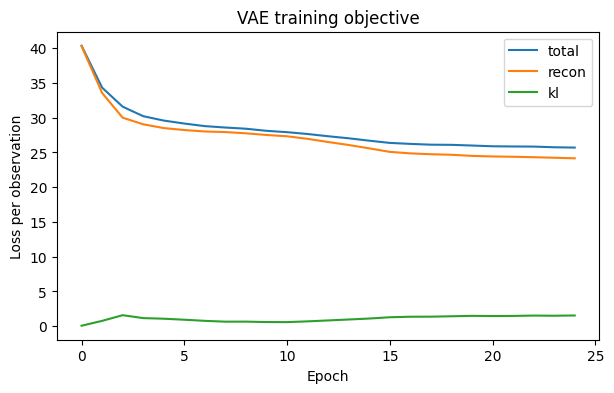

In [42]:
plt.figure(figsize=(7,4))
for key in ["total","recon","kl"]: plt.plot(history[key],label=key)
plt.xlabel("Epoch"); plt.ylabel("Loss per observation")
plt.title("VAE training objective"); plt.legend(); plt.show()

## 3.6 Held-out reconstruction
This is a reconstruction assessment, not a complete evaluation of generative quality.

In [43]:
vae.eval(); recs=[]; mus=[]; logvars=[]
with torch.no_grad():
    for (x,) in test_loader:
        recon,mu,lv=vae(x.to(device))
        recs.append(recon.cpu().numpy()); mus.append(mu.cpu().numpy()); logvars.append(lv.cpu().numpy())
Xrec=np.concatenate(recs); Zmu=np.concatenate(mus); Zlv=np.concatenate(logvars)
print("Test reconstruction MSE:",mean_squared_error(Xte,Xrec))

Test reconstruction MSE: 0.05507347732782364


## 3.7 Optional comparison — Deterministic AE vs. VAE

A basic Autoencoder produces a deterministic latent code. A VAE produces a distribution and regularizes it toward a prior. The following compact deterministic AE uses the same input and latent dimensions. Compare its held-out reconstruction MSE with the VAE result above. The comparison is illustrative: the two objectives are different, so reconstruction error alone does not measure all model capabilities.

In [ ]:
class BasicAE(nn.Module):
    def __init__(self, input_dim=64, hidden_dim=128, latent_dim=2):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(input_dim, hidden_dim), nn.ReLU(),
                                     nn.Linear(hidden_dim, latent_dim))
        self.decoder = nn.Sequential(nn.Linear(latent_dim, hidden_dim), nn.ReLU(),
                                     nn.Linear(hidden_dim, input_dim), nn.Sigmoid())
    def forward(self, x):
        return self.decoder(self.encoder(x))

ae = BasicAE(latent_dim=2).to(device)
ae_opt = torch.optim.Adam(ae.parameters(), lr=1e-3)
ae_history = []
for epoch in range(25):
    ae.train()
    total = 0.0
    for (xb,) in train_loader:
        xb = xb.to(device)
        ae_opt.zero_grad()
        xb_hat = ae(xb)
        loss = nn.functional.binary_cross_entropy(xb_hat, xb, reduction="sum")
        loss.backward()
        ae_opt.step()
        total += loss.item()
    ae_history.append(total / len(Xtr))

ae.eval()
ae_preds = []
with torch.no_grad():
    for (xb,) in test_loader:
        ae_preds.append(ae(xb.to(device)).cpu().numpy())
ae_preds = np.concatenate(ae_preds)
ae_test_mse = mean_squared_error(Xte, ae_preds)
print("Basic AE test MSE:", ae_test_mse)
print("VAE test MSE:", mean_squared_error(Xte, Xrec))

Basic AE test MSE: 0.051706306636333466
VAE test MSE: 0.05507347732782364


**Interpretation guide:** If the Basic AE has lower reconstruction error, this is not a failure of the VAE. The VAE pays an additional KL-regularization cost to organize its latent distribution and support prior sampling. The Basic AE does not, by default, provide a meaningful prior from which new samples can be generated.

# Experiment 4 — Latent-space analysis

## 4.1 Visualize posterior means
For visualization, we plot posterior means $
\mu_\phi(x)\
$. Color indicates the digit label. A two-dimensional latent space is convenient to inspect but is not necessarily sufficient for every dataset or task.

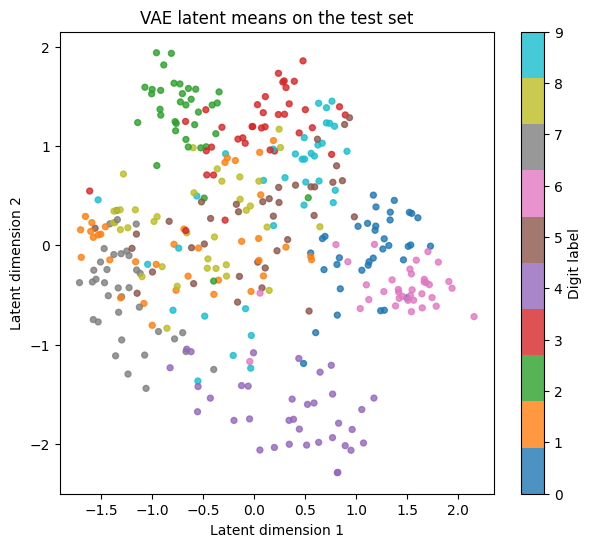

In [44]:
fig,ax=plt.subplots(figsize=(7,6))
sc=ax.scatter(Zmu[:,0],Zmu[:,1],c=yte,cmap="tab10",s=18,alpha=.8)
ax.set(title="VAE latent means on the test set",xlabel="Latent dimension 1",ylabel="Latent dimension 2")
plt.colorbar(sc,ax=ax,label="Digit label"); plt.show()

## 4.2 Interpolate between two observations
Linear interpolation in latent space illustrates how the decoder changes between two encoded observations. It does not prove that every interpolated point is realistic.

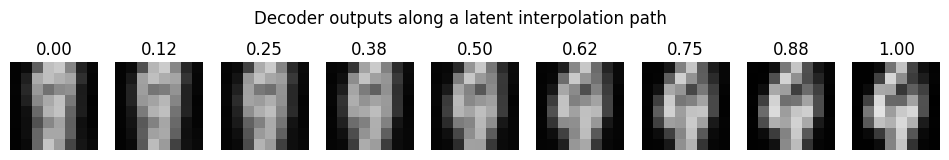

In [45]:
vae.eval()
za=torch.tensor(Zmu[3],dtype=torch.float32,device=device)
zb=torch.tensor(Zmu[17],dtype=torch.float32,device=device)
weights=torch.linspace(0,1,9,device=device)
with torch.no_grad():
    zpath=torch.stack([(1-w)*za+w*zb for w in weights])
    inter=vae.decode(zpath).cpu().numpy()
fig,axes=plt.subplots(1,9,figsize=(12,2))
for ax,img,w in zip(axes,inter,weights.cpu().numpy()):
    ax.imshow(img.reshape(8,8),cmap="gray",vmin=0,vmax=1); ax.set_title(f"{w:.2f}"); ax.axis("off")
plt.suptitle("Decoder outputs along a latent interpolation path"); plt.show()

## 4.3 Generate samples from the prior
The VAE is trained with a standard normal prior. We can sample from that prior and decode the latent vectors. Outputs may be blurry or ambiguous because the dataset and network are small and training is intentionally brief.

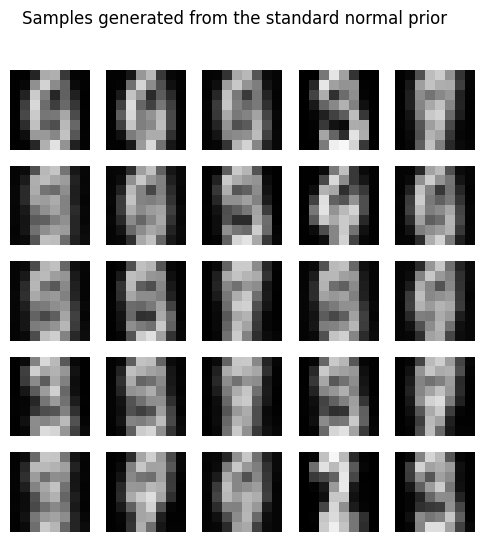

In [46]:
with torch.no_grad():
    z=torch.randn(25,2,device=device)
    generated=vae.decode(z).cpu().numpy()
fig,axes=plt.subplots(5,5,figsize=(6,6))
for ax,img in zip(axes.ravel(),generated):
    ax.imshow(img.reshape(8,8),cmap="gray",vmin=0,vmax=1); ax.axis("off")
plt.suptitle("Samples generated from the standard normal prior"); plt.show()

## 4.4 What does the KL weight change?
The KL term encourages the approximate posterior to remain close to the prior. If its weight is too small, latent codes may become irregular and prior samples may decode poorly. If it is too large, the model may prioritize matching the prior at the expense of reconstruction detail.

A rigorous comparison requires separately trained models under controlled settings and evaluation of both reconstruction and generation.

## 4.5 Optional experiment — KL-weight sensitivity (β-VAE idea)

The parameter $\beta$ changes the trade-off between reconstruction and latent regularization. To keep this optional run short, train a second VAE with a larger KL weight. Compare its reconstruction loss and KL term with the standard VAE. Results can vary with initialization and training duration.

Epoch 05/12 | total 30.395 | recon 30.158 | KL 0.079
Epoch 10/12 | total 28.183 | recon 28.130 | KL 0.018


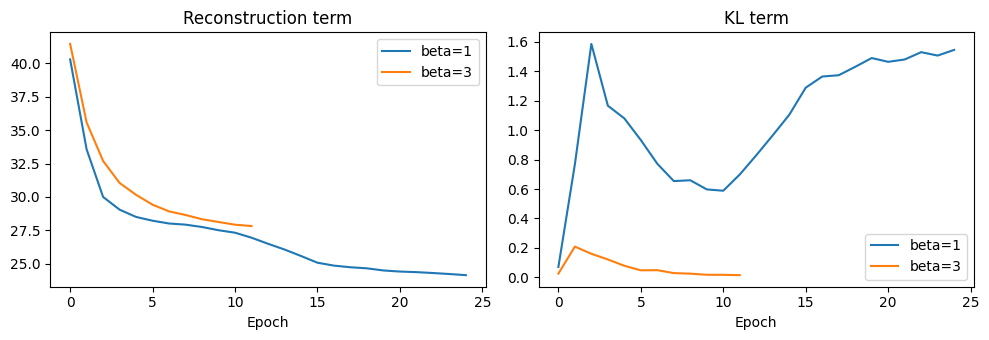

In [48]:
vae_beta = VAE(latent_dim=2).to(device)
beta_history = train_vae(vae_beta, train_loader, epochs=12, beta=3.0)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(history["recon"], label="beta=1")
ax[0].plot(beta_history["recon"], label="beta=3")
ax[0].set_title("Reconstruction term"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(history["kl"], label="beta=1")
ax[1].plot(beta_history["kl"], label="beta=3")
ax[1].set_title("KL term"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

**Expected interpretation:** A larger $\beta$ places more pressure on the latent posterior to resemble the prior. It often reduces the KL term but may increase reconstruction error or slow its improvement. Do not expect a perfectly monotonic result from a short stochastic training run.

# Optional Extensions

These sections are for interested students and are not required for the live-session core.

## Optional A — Conditional VAE (CVAE)
A CVAE conditions both the encoder and decoder on an auxiliary variable such as a class label:

$$
q_\phi(z|x,y),\qquad p_\theta(x|z,y).
$$

For digit generation, the label can guide the decoder toward a desired class. **Explore:** What changes in the model inputs and sampling procedure when the desired class is supplied?

## Optional B — Contractive Autoencoder (CAE)
A Contractive AE adds a penalty on the encoder Jacobian:

$$
\mathcal{L}_{CAE}=\mathcal{L}_{recon}
+\lambda\left\|\frac{\partial f_\phi(x)}{\partial x}\right\|_F^2.
$$

It encourages local insensitivity to small input perturbations. This differs from a Denoising AE, which learns to reconstruct clean inputs from corrupted inputs.

## Optional C — Stacked Autoencoder
A Stacked AE uses multiple encoder and decoder layers to learn hierarchical representations. Explore how depth and bottleneck size affect reconstruction and optimization.

## Optional D — β-VAE and VQ-VAE
- **β-VAE:** changes the relative weight of the KL term. A larger weight strengthens pressure toward the prior but may reduce reconstruction fidelity.
- **VQ-VAE:** uses a learned discrete codebook and vector quantization instead of continuous latent codes.

These are conceptual extensions, not additional implementations in this session.

# Optional Extensions — Implementations and guided answers

The following cells provide small, runnable demonstrations. They are extensions, not required parts of the one-hour live session.

## Optional A — Conditional VAE (CVAE)

A CVAE receives the class label as additional information in both the encoder and decoder. Here labels are one-hot encoded. The model learns \(q(z|x,y)\) and decodes from \(p(x|z,y)\).

In [49]:
class CVAE(nn.Module):
    def __init__(self, input_dim=64, n_classes=10, hidden_dim=128, latent_dim=2):
        super().__init__()
        self.n_classes=n_classes
        self.enc=nn.Sequential(nn.Linear(input_dim+n_classes,hidden_dim),nn.ReLU())
        self.mu=nn.Linear(hidden_dim,latent_dim)
        self.logvar=nn.Linear(hidden_dim,latent_dim)
        self.dec=nn.Sequential(nn.Linear(latent_dim+n_classes,hidden_dim),nn.ReLU(),
                               nn.Linear(hidden_dim,input_dim),nn.Sigmoid())
    def one_hot(self,y):
        return nn.functional.one_hot(y.long(),num_classes=self.n_classes).float()
    def forward(self,x,y):
        yoh=self.one_hot(y)
        h=self.enc(torch.cat([x,yoh],dim=1))
        mu,lv=self.mu(h),self.logvar(h)
        z=mu+torch.exp(0.5*lv)*torch.randn_like(lv)
        recon=self.dec(torch.cat([z,yoh],dim=1))
        return recon,mu,lv

**Guided answer:** The label is concatenated to the input of the encoder and to the latent vector entering the decoder. At generation time, choose a label, sample 
$
z\sim\mathcal N(0,I)\
$, and decode the pair \((z,y)\). Conditioning provides control over the requested class; it does not guarantee perfect class-consistent samples.

In [50]:
# One forward-pass demonstration with a small batch.
cvae=CVAE(latent_dim=2).to(device)
xb=torch.tensor(Xtr[:8],dtype=torch.float32,device=device)
yb=torch.tensor(load_digits().target[train_test_split(
    np.arange(len(Xdigits)),test_size=0.2,random_state=SEED,
    stratify=load_digits().target)[0][:8]],dtype=torch.long,device=device)
with torch.no_grad():
    c_recon,c_mu,c_lv=cvae(xb,yb)
print("CVAE reconstruction shape:",tuple(c_recon.shape))
print("Condition labels:",yb.cpu().tolist())

CVAE reconstruction shape: (8, 64)
Condition labels: [5, 0, 5, 7, 1, 2, 9, 9]


## Optional B — Contractive Autoencoder (CAE)

A Contractive AE penalizes the sensitivity of the encoder representation to small input changes. The Jacobian penalty is 
$
\|J_f(x)\|_F^2\
$. For a small batch and low-dimensional latent space, it can be computed directly with automatic differentiation.

In [51]:
class ContractiveAE(nn.Module):
    def __init__(self, input_dim=64, hidden_dim=64, latent_dim=8):
        super().__init__()
        self.encoder=nn.Sequential(nn.Linear(input_dim,hidden_dim),nn.Tanh(),
                                   nn.Linear(hidden_dim,latent_dim))
        self.decoder=nn.Sequential(nn.Linear(latent_dim,hidden_dim),nn.Tanh(),
                                   nn.Linear(hidden_dim,input_dim),nn.Sigmoid())
    def forward(self,x):
        z=self.encoder(x)
        return self.decoder(z),z

cae=ContractiveAE().to(device)
xb=torch.tensor(Xtr[:32],dtype=torch.float32,device=device).requires_grad_(True)
xhat,z=cae(xb)
rec_loss=nn.functional.mse_loss(xhat,xb)
jacobian_penalty=0.0
for j in range(z.shape[1]):
    grad_j=torch.autograd.grad(z[:,j].sum(),xb,create_graph=True,retain_graph=True)[0]
    jacobian_penalty=jacobian_penalty+grad_j.pow(2).sum(dim=1).mean()
cae_loss=rec_loss+1e-3*jacobian_penalty
print("Reconstruction loss:",float(rec_loss.detach()))
print("Jacobian penalty:",float(jacobian_penalty.detach()))
print("Combined CAE loss:",float(cae_loss.detach()))

Reconstruction loss: 0.18372437357902527
Jacobian penalty: 0.7223479747772217
Combined CAE loss: 0.18444672226905823


**Guided answer:** The Jacobian term discourages large changes in the latent code caused by small changes in the input. Unlike a Denoising AE, this implementation does not corrupt the input; it explicitly penalizes local encoder sensitivity. The direct Jacobian calculation is computationally expensive for large inputs or latent spaces.

## Optional C — Stacked / deeper Autoencoder

A deeper encoder-decoder can learn a hierarchy of nonlinear transformations. The following example uses multiple hidden layers while keeping the same 64-dimensional input.

In [52]:
class StackedAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder=nn.Sequential(nn.Linear(64,128),nn.ReLU(),
                                   nn.Linear(128,64),nn.ReLU(),
                                   nn.Linear(64,2))
        self.decoder=nn.Sequential(nn.Linear(2,64),nn.ReLU(),
                                   nn.Linear(64,128),nn.ReLU(),
                                   nn.Linear(128,64),nn.Sigmoid())
    def forward(self,x): return self.decoder(self.encoder(x))

stacked_ae=StackedAE().to(device)
opt=torch.optim.Adam(stacked_ae.parameters(),lr=1e-3)
for epoch in range(8):
    stacked_ae.train(); total=0
    for (xb,) in train_loader:
        xb=xb.to(device); opt.zero_grad()
        loss=nn.functional.binary_cross_entropy(stacked_ae(xb),xb,reduction="sum")
        loss.backward(); opt.step(); total+=loss.item()
    print(f"Epoch {epoch+1}: train BCE per sample = {total/len(Xtr):.3f}")

Epoch 1: train BCE per sample = 43.034
Epoch 2: train BCE per sample = 35.580
Epoch 3: train BCE per sample = 28.933
Epoch 4: train BCE per sample = 27.609
Epoch 5: train BCE per sample = 27.231
Epoch 6: train BCE per sample = 27.130
Epoch 7: train BCE per sample = 27.066
Epoch 8: train BCE per sample = 27.016


**Guided answer:** Depth increases representational flexibility but also adds optimization complexity and can overfit. Compare models using held-out reconstruction, not training loss alone. A deeper model is not automatically better.

## Optional D — Vector-Quantized VAE (VQ-VAE): codebook demonstration

VQ-VAE maps encoder outputs to their nearest learned codebook vector. This creates a discrete latent representation. The cell below demonstrates the core quantization operation and its straight-through gradient estimator; it is a compact component demonstration rather than a fully trained VQ-VAE.

In [53]:
class VectorQuantizer(nn.Module):
    def __init__(self,n_codes=32,embedding_dim=16,beta=0.25):
        super().__init__()
        self.embedding=nn.Embedding(n_codes,embedding_dim)
        self.embedding.weight.data.uniform_(-1/n_codes,1/n_codes)
        self.beta=beta
    def forward(self,z_e):
        # z_e shape: [batch, embedding_dim]
        distances=(z_e.pow(2).sum(1,keepdim=True)
                   +self.embedding.weight.pow(2).sum(1)
                   -2*z_e@self.embedding.weight.t())
        indices=distances.argmin(dim=1)
        z_q=self.embedding(indices)
        codebook_loss=nn.functional.mse_loss(z_q,z_e.detach())
        commitment_loss=nn.functional.mse_loss(z_e,z_q.detach())
        loss=codebook_loss+self.beta*commitment_loss
        z_st=z_e+(z_q-z_e).detach()
        return z_st,indices,loss

vq=VectorQuantizer(n_codes=16,embedding_dim=8)
z_example=torch.randn(12,8)
z_quantized,code_ids,vq_loss=vq(z_example)
print("Input shape:",tuple(z_example.shape))
print("Quantized shape:",tuple(z_quantized.shape))
print("Selected code indices:",code_ids.tolist())
print("Quantization loss:",float(vq_loss))

Input shape: (12, 8)
Quantized shape: (12, 8)
Selected code indices: [2, 12, 11, 13, 8, 2, 6, 14, 15, 1, 11, 8]
Quantization loss: 1.1681581735610962


**Guided answer:** Each continuous encoder vector is replaced by its nearest codebook entry. The codebook loss updates embeddings, while the commitment loss encourages encoder outputs to stay near selected entries. The straight-through estimator passes gradients from the decoder path to the encoder despite the discrete nearest-neighbor operation. Unlike a standard VAE, VQ-VAE uses discrete code indices rather than a Gaussian latent posterior.

## Optional E — CVAE sampling: choose a class

The trained CVAE above is only initialized, not trained, so its outputs are not meaningful yet. This final cell shows the **sampling interface**. Train the CVAE on labeled batches before interpreting the generated images.

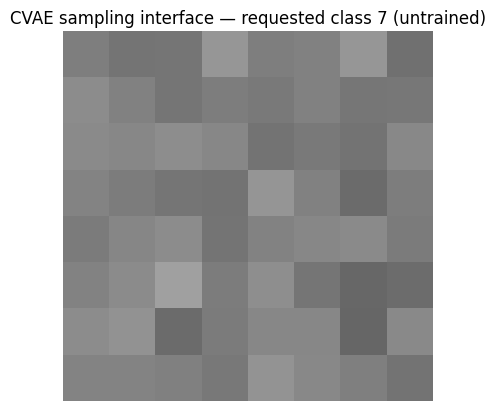

In [54]:
# Sampling interface (untrained demonstration; outputs are random at this stage).
chosen_digit=7
with torch.no_grad():
    z=torch.randn(1,2,device=device)
    label=torch.tensor([chosen_digit],device=device)
    yoh=cvae.one_hot(label)
    sample=cvae.dec(torch.cat([z,yoh],dim=1)).cpu().numpy().reshape(8,8)
plt.imshow(sample,cmap="gray",vmin=0,vmax=1)
plt.title(f"CVAE sampling interface — requested class {chosen_digit} (untrained)")
plt.axis("off"); plt.show()

# Final comparison

| Method | Representation assumption | What it adds | Typical limitation |
|---|---|---|---|
| PCA | Linear low-dimensional subspace | Variance-preserving projection | Misses nonlinear geometry |
| Kernel PCA | Similarity defined by a kernel | Nonlinear feature-space PCA | Kernel choice and computational scaling |
| Fixed-dictionary sparse coding | Sparse combination of predefined atoms | Compact signal representation | Dictionary may not match the data |
| Dictionary learning | Sparse combination of learned atoms | Data-adapted dictionary | Non-convex alternating optimization |
| Basic Autoencoder | Deterministic learned code | Nonlinear encoder-decoder | No explicit prior for sampling |
| VAE | Probabilistic latent code | Regularized latent distribution and sampling | Reconstruction–regularization trade-off |

## Take-home questions
1. What assumption does Kernel PCA relax compared with ordinary PCA?
2. Why can Kernel PCA still produce a poor representation?
3. What is learned in Dictionary Learning that is fixed in ordinary sparse coding?
4. Why does lower training reconstruction error not guarantee a better dictionary?
5. What is the role of KL divergence in a VAE?
6. Why is the reparameterization trick needed?
7. How are latent interpolation and prior sampling different?
8. In what sense is a VAE generative while a basic Autoencoder is not automatically generative?

## References
- Schölkopf, B., Smola, A., & Müller, K.-R. (1998). *Nonlinear Component Analysis as a Kernel Eigenvalue Problem*. Neural Computation. https://doi.org/10.1162/089976698300017467
- Aharon, M., Elad, M., & Bruckstein, A. (2006). *K-SVD: An Algorithm for Designing Overcomplete Dictionaries for Sparse Representation*. IEEE Transactions on Signal Processing. https://doi.org/10.1109/TSP.2006.881199
- Kingma, D. P., & Welling, M. (2014). *Auto-Encoding Variational Bayes*. https://arxiv.org/abs/1312.6114
- PyTorch Tutorials — Learn the Basics: https://docs.pytorch.org/tutorials/beginner/basics/intro.html
- PyTorch — Autograd Mechanics: https://docs.pytorch.org/docs/stable/notes/autograd.html
- scikit-learn — KernelPCA: https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.KernelPCA.html
- scikit-learn — DictionaryLearning: https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.DictionaryLearning.html

**Closing message:** Representation learning is not one algorithm. It is a choice about what structure the model should assume, discover, or generate.